<a href="https://colab.research.google.com/github/JanhaviK30/AIML-B-3rd-year-repo/blob/main/LOAN_DEFAULT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv('/content/loan_default.csv')
df.shape; df.info(); df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1012 non-null   object 
 1   age                1012 non-null   int64  
 2   income             1012 non-null   float64
 3   loan_amount        1012 non-null   float64
 4   credit_score       1012 non-null   float64
 5   employment_years   1012 non-null   float64
 6   debt_to_income     1012 non-null   float64
 7   existing_loans     1012 non-null   int64  
 8   dependents         1012 non-null   int64  
 9   bank_balance       1012 non-null   float64
 10  interest_rate      1012 non-null   float64
 11  employment_type    1012 non-null   object 
 12  marital_status     1012 non-null   object 
 13  education          951 non-null    object 
 14  loan_purpose       1012 non-null   object 
 15  city_tier          1012 non-null   object 
 16  previous_defaults  1012 

,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
0,CUST00084,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,Contract,Married,High School,Business,Tier 3,2,No
1,CUST00543,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,Salaried,Single,Graduate,Education,Tier 1,0,No
2,CUST00718,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,Contract,Married,High School,Personal,Tier 1,1,No
3,CUST00240,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,Salaried,Single,High School,Education,Tier 1,0,No
4,CUST00649,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,Salaried,Married,Undergraduate,Education,Tier 1,1,No
5,CUST00363,51,43421.0,203423.0,591.0,10.0,0.488,1,0,6242.09,9.82,Salaried,Single,Postgraduate,Education,Tier 1,1,No
6,CUST00302,32,61240.0,219736.0,653.0,7.3,0.460,1,2,564.28,9.22,Contract,Divorced,NaN,Business,Tier 2,1,No
7,CUST00568,43,75088.0,208966.0,635.0,17.5,0.469,0,3,11137.85,9.96,Salaried,Divorced,Undergraduate,Business,Tier 1,1,No
8,CUST00086,43,62544.0,328632.0,640.0,8.0,0.369,0,0,16709.98,9.59,Contract,Married,Graduate,Education,Tier 2,0,No
9,CUST00600,38,54997.0,273677.0,656.0,10.4,0.372,2,3,8650.50,9.71,Salaried,Single,Graduate,Business,Tier 1,0,No


In [ ]:
df = df.drop(columns=['customer_id'])
df['loan_default'] = df['loan_default'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, drop_first=True)
X = df.drop('loan_default', axis=1); y = df['loan_default']


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print(dt.score(X_train, y_train), dt.score(X_test, y_test))


1.0 0.7241379310344828


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score

In [ ]:
from sklearn.model_selection import GridSearchCV

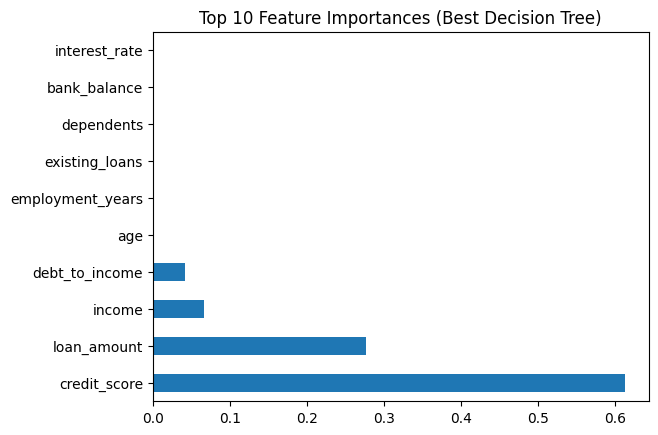

In [ ]:
from sklearn.tree import plot_tree

# Define parameter grid and run GridSearch to find the 'best' model
param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
best = grid_search.best_estimator_

# Now plot the feature importances from the 'best' model
pd.Series(best.feature_importances_, index=X.columns).nlargest(10).plot(kind='barh')
plt.title('Top 10 Feature Importances (Best Decision Tree)')
plt.show()